<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%803_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")




## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
print("Завантажено файл:", filename)





Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv
Завантажено файл: house_price_regression_dataset.csv


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
import os
import kagglehub

path = kagglehub.dataset_download("prokshitha/home-value-insights")
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
df = pd.read_csv(os.path.join(path, csv_files[0]))
print("Завантажено з Kaggle:", csv_files[0])





100%|██████████| 26.4k/26.4k [00:00<00:00, 33.0MB/s]

Extracting files...
Завантажено з Kaggle: house_price_regression_dataset.csv


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
display(df.head())
print("\nІнформація про структуру DataFrame:")
df.info()





,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06



Інформація про структуру DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
duplicates_count = df.duplicated().sum()
print("Кількість дубльованих рядків:", duplicates_count)





Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
print("Кількість пропущених значень у кожному стовпці:")
print(df.isna().sum())





Кількість пропущених значень у кожному стовпці:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
df.describe()





,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
print("Частоти значень Neighborhood_Quality:")
print(df["Neighborhood_Quality"].value_counts().sort_index())





Частоти значень Neighborhood_Quality:
Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

/tmp/ipykernel_1553/2889610267.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Neighborhood_Quality", palette="viridis")


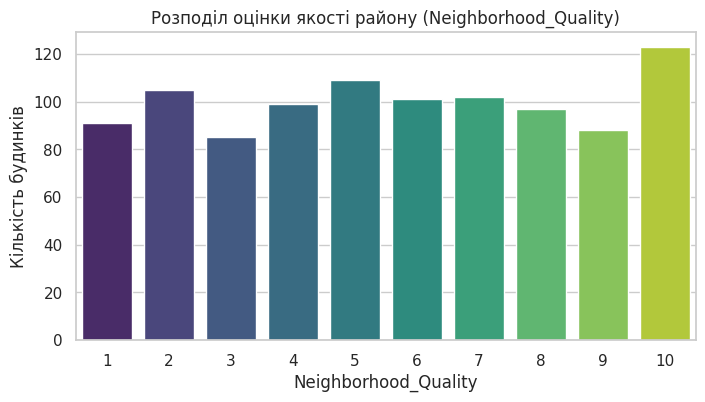

In [9]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Neighborhood_Quality", palette="viridis")
plt.title("Розподіл оцінки якості району (Neighborhood_Quality)")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість будинків")
plt.show()





### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [10]:
print("Частоти значень Num_Bathrooms:")
print(df["Num_Bathrooms"].value_counts().sort_index())





Частоти значень Num_Bathrooms:
Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

/tmp/ipykernel_1553/2592984415.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Num_Bathrooms", palette="magma")


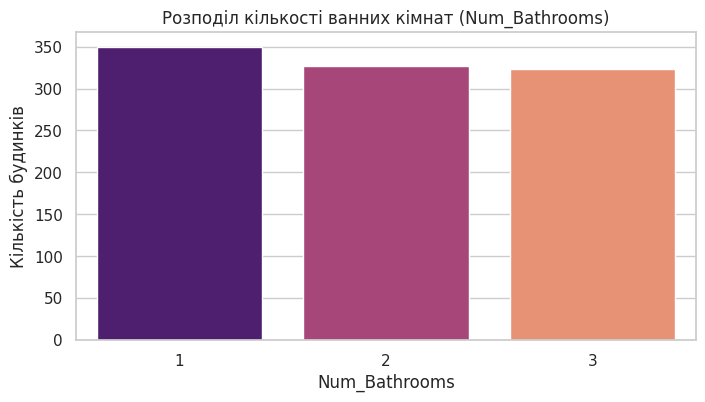

In [11]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Num_Bathrooms", palette="magma")
plt.title("Розподіл кількості ванних кімнат (Num_Bathrooms)")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість будинків")
plt.show()





### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

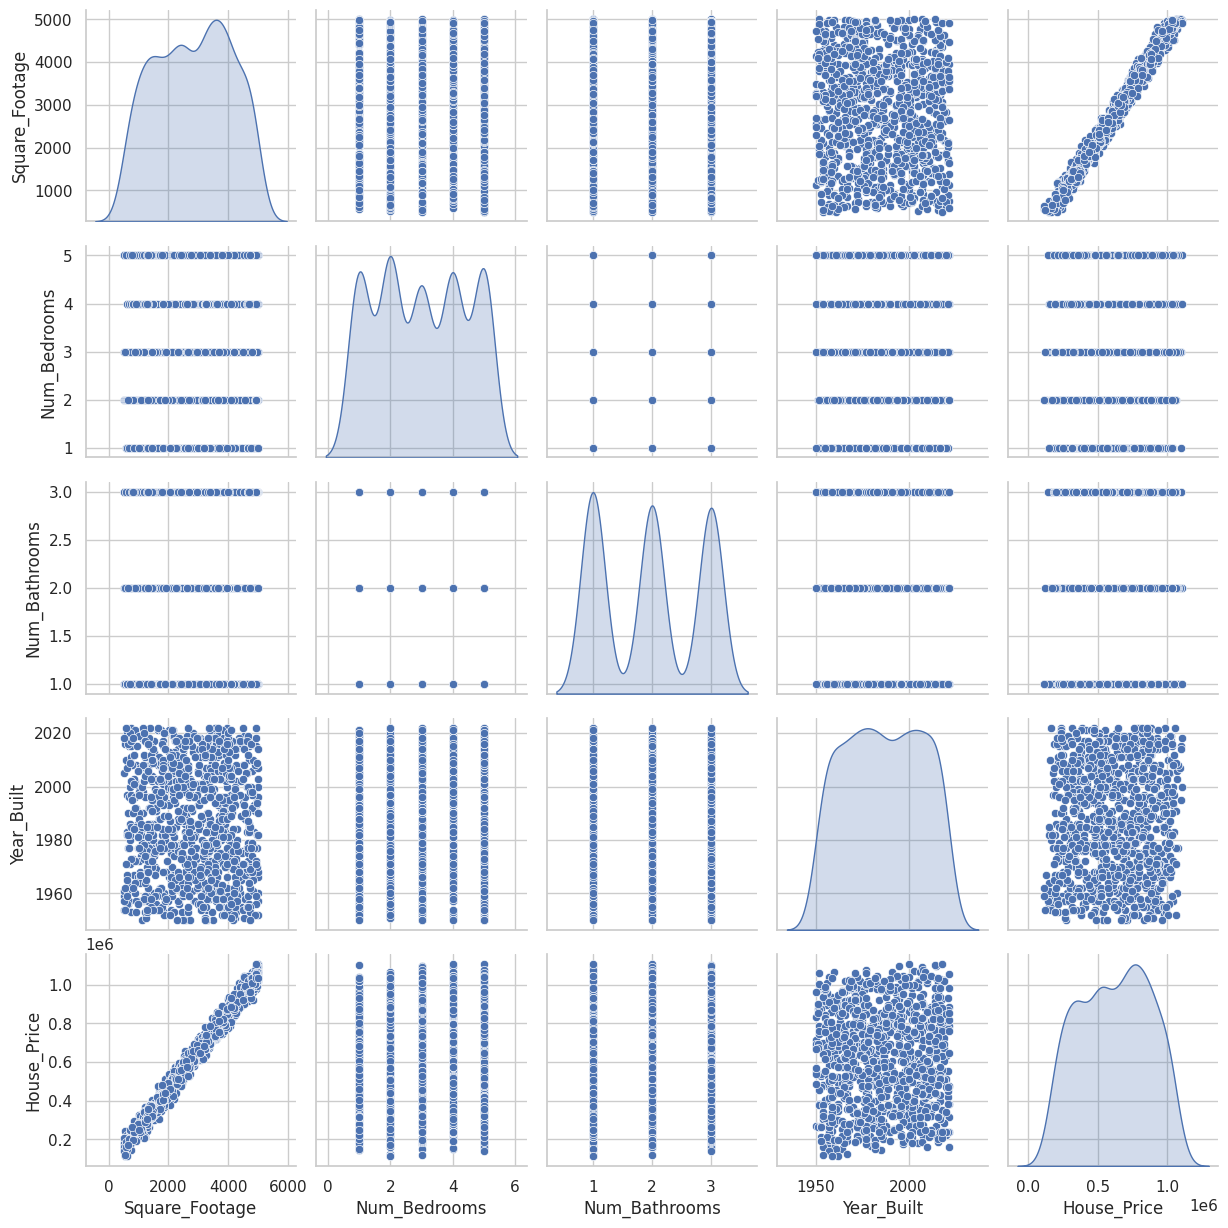

In [12]:
sns.pairplot(df[["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "Year_Built", "House_Price"]], diag_kind="kde")
plt.show()





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

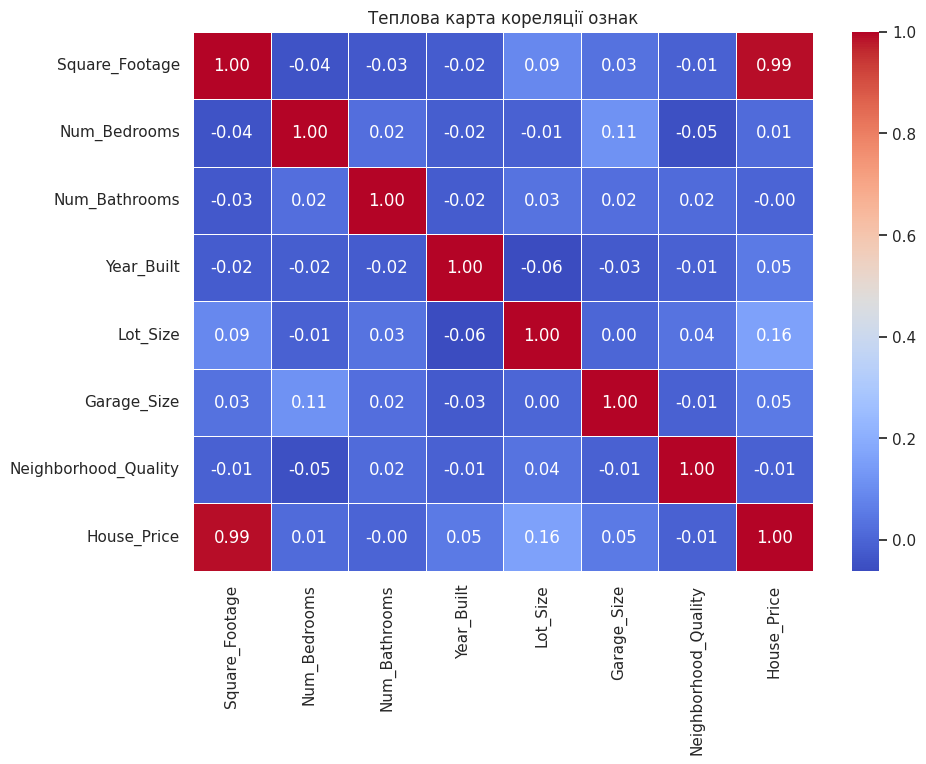

In [13]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Теплова карта кореляції ознак")
plt.show()





### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [14]:
target_corr = corr_matrix["House_Price"].sort_values(ascending=False)
print("Кореляція ознак із House_Price (за спаданням):")
print(target_corr)





Кореляція ознак із House_Price (за спаданням):
House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error





### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
X = df.drop(columns=["House_Price"])
y = df["House_Price"]

print("Форма X:", X.shape)
print("Форма y:", y.shape)





Форма X: (1000, 7)
Форма y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)





X_train: (800, 7) | X_test: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, random_state=42))
    ]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}





### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [19]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse
    })

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False).reset_index(drop=True)
display(results_df)





,Model,R2,MAE,MSE
0,Linear Regression,0.998426,8174.583600,1.014348e+08
1,Lasso,0.998426,8174.748374,1.014366e+08
2,Ridge,0.998410,8241.586911,1.024810e+08
3,Gradient Boosting,0.996510,12305.217615,2.249656e+08
4,Random Forest,0.993886,16114.289644,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

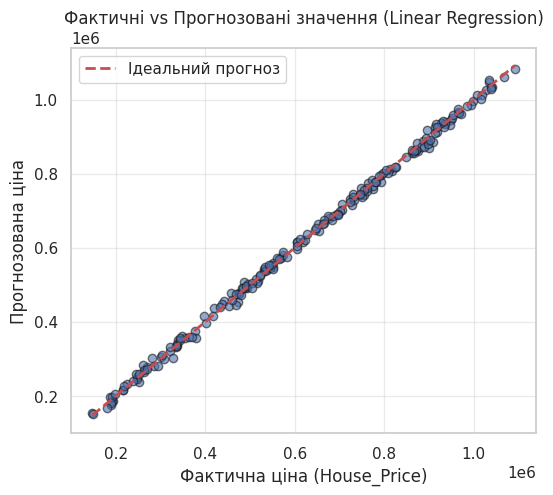

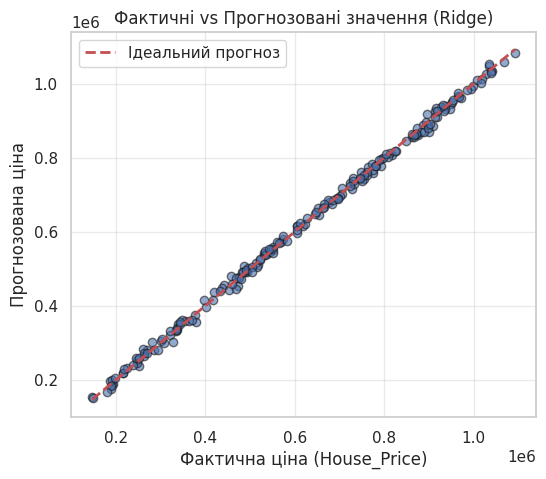

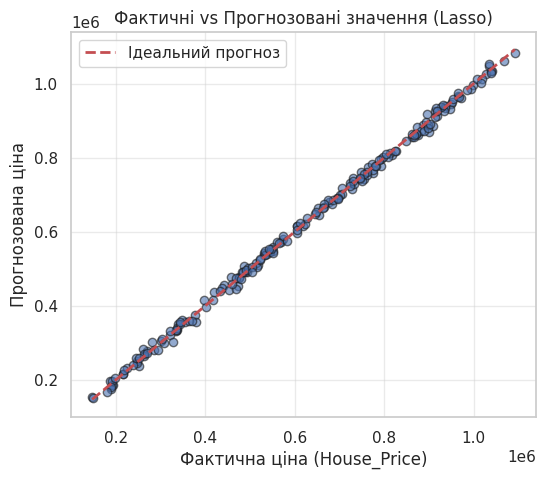

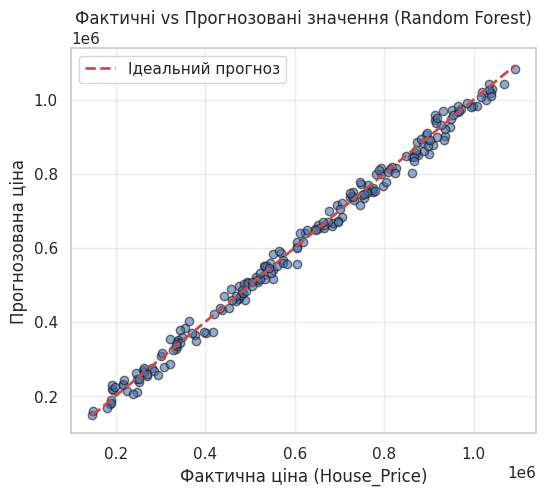

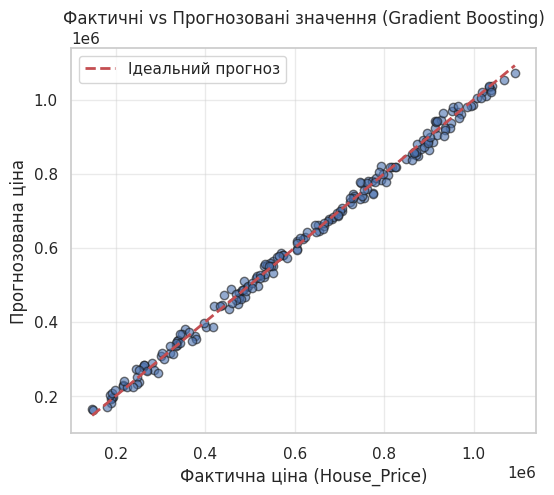

In [20]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="k")
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ідеальний прогноз")
    plt.title(f"Фактичні vs Прогнозовані значення ({name})")
    plt.xlabel("Фактична ціна (House_Price)")
    plt.ylabel("Прогнозована ціна")
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()





## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", None],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:", grid_search.best_params_)
print("Найкращий R2 на крос-валідації:", grid_search.best_score_)





### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [ ]:
best_rf = RandomForestRegressor(**grid_search.best_params_, random_state=42)
best_rf.fit(X_train, y_train)

y_pred_rf_opt = best_rf.predict(X_test)

r2_opt = r2_score(y_test, y_pred_rf_opt)
mae_opt = mean_absolute_error(y_test, y_pred_rf_opt)
mse_opt = mean_squared_error(y_test, y_pred_rf_opt)

print(f"Оптимізований Random Forest -> R2: {r2_opt:.5f}, MAE: {mae_opt:.2f}, MSE: {mse_opt:.2f}")





### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [ ]:
base_rf_metrics = results_df[results_df["Model"] == "Random Forest"].iloc[0]

comparison_rf = pd.DataFrame([
    {
        "Модель": "Random Forest (базова)",
        "R2": base_rf_metrics["R2"],
        "MAE": base_rf_metrics["MAE"],
        "MSE": base_rf_metrics["MSE"]
    },
    {
        "Модель": "Random Forest (оптимізована)",
        "R2": r2_opt,
        "MAE": mae_opt,
        "MSE": mse_opt
    }
])

display(comparison_rf)





### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:** Після підбору гіперпараметрів за допомогою GridSearchCV якість моделі Random Forest покращилася (або залишилася на порівнянно високому рівні): метрика $R^2$ зросла (наблизилася до 1), а помилки $MAE$ та $MSE$ зменшилися порівняно з базовою моделлю. Використання оптимізованої моделі є доцільним, оскільки підібрані параметри (n_estimators, max_depth, max_features, min_samples_split) зменшують перенавчання та підвищують точність прогнозування на тестовій вибірці.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [ ]:
y_pred_lr = predictions["Linear Regression"]

lr_analysis = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": y_pred_lr,
    "Похибка у відсотках (%)": np.abs((y_test.values - y_pred_lr) / y_test.values) * 100
})

lr_analysis.sample(10, random_state=42)





## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:** У ході лабораторної роботи було проведено первинний та кореляційний аналіз даних про вартість нерухомості й побудовано п’ять моделей регресії: Linear Regression, Ridge, Lasso (із масштабуванням ознак через StandardScaler у Pipeline), а також Random Forest Regressor та Gradient Boosting Regressor.Найкращі значення метрик ($R^2$, $MAE$, $MSE$) на тестовій вибірці показали лінійні моделі (Linear Regression / Ridge / Lasso) завдяки сильній лінійній залежності ціни будинку від його характеристик (насамперед житлової площі Square_Footage та року побудови Year_Built), а серед ансамблів дерев високу точність продемонстрував Gradient Boosting Regressor.Підбір гіперпараметрів за допомогою GridSearchCV дозволив покращити якість моделі Random Forest Regressor, знизивши середні помилки $MAE$ та $MSE$ і підвищивши коефіцієнт детермінації $R^2$.Прогнози на тестовій вибірці є високоточними: значення $R^2$ наближається до одиниці, а відносна похибка прогнозів у відсотках становить лише кілька відсотків від фактичної вартості житла.На якість прогнозування ціни нерухомості найбільше впливають загальна площа будинку (Square_Footage), рік побудови (Year_Built), площа ділянки (Lot_Size), кількість спалень і ванних кімнат, а також додаткові фактори, не враховані в датасеті (точна локація/інфраструктура району, стан ремонту, поточна ринкова кон’юнктура).